In [1]:
import numpy as np
import pandas as pd
import sys
sys.path.insert(0, '.')

from Engine.TickData import TickData
from Engine.Backtester import Backtester


Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Analyzing 60 tick intervals (Williams fractals)...
Aggregated 23,033,489 ticks into 460,669 bars (50 tick)
Aggregated 23,033,489 ticks into 230,334 bars (100 tick)
Aggregated 23,033,489 ticks into 153,556 bars (150 tick)
Aggregated 23,033,489 ticks into 115,167 bars (200 tick)
Aggregated 23,033,489 ticks into 92,133 bars (250 tick)
Aggregated 23,033,489 ticks into 76,778 bars (300 tick)
Aggregated 23,033,489 ticks into 65,809 bars (350 tick)
Aggregated 23,033,489 ticks into 57,583 bars (400 tick)
Aggregated 23,033,489 ticks into 51,185 bars (450 tick)
Aggregated 23,033,489 ticks into 46,066 bars (500 tick)
Aggregated 23,033,489 ticks into 41,879 bars (550 tick)
Aggregated 23,033,489 ticks into 38,389 bars (600 tick)
Aggregated 23,033,489 ticks into 35,436 bars (650 tick)
Aggregated 23,033,489 ticks into 32,904 bars (700 tick)
Aggregated 23,033,489 ticks into 30,711 bars (750 tick)
Aggregated 2

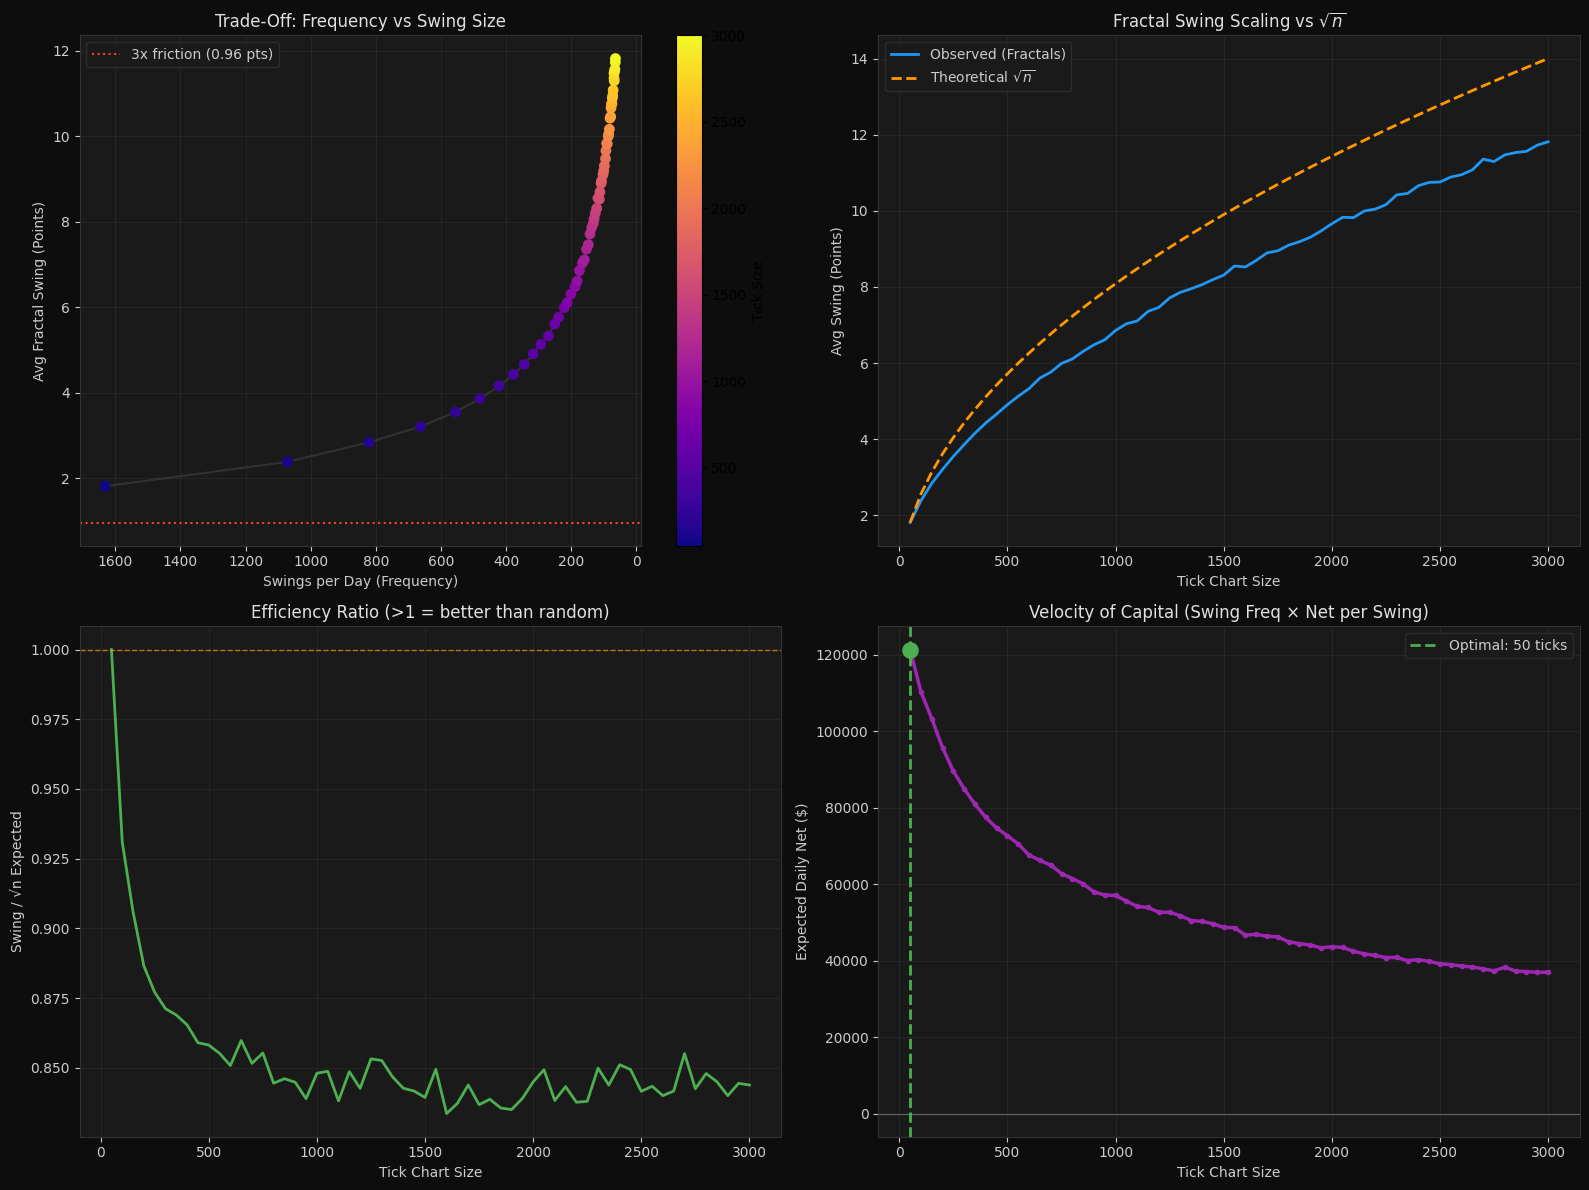


Optimal tick size by daily velocity: 50 ticks ($121,349/day)



Tick Size,Avg Swing (pts),Avg Swing ($),Swings/Day,Net/Swing ($),Daily Net ($)
50,1.808,$90.38,1631.4,$74.38,"$121,349"
100,2.380,$119.00,1071.0,$103.00,"$110,307"
150,2.836,$141.82,821.1,$125.82,"$103,312"
200,3.205,$160.25,663.1,$144.25,"$95,647"
250,3.545,$177.25,555.3,$161.25,"$89,550"
300,3.857,$192.87,480.1,$176.87,"$84,911"
350,4.156,$207.78,421.8,$191.78,"$80,886"
400,4.424,$221.22,377.3,$205.22,"$77,438"
450,4.658,$232.90,344.3,$216.90,"$74,672"
500,4.905,$245.26,316.8,$229.26,"$72,624"


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

td = TickData('./Data/ESTick.txt', timezone='America/Chicago')

# Parameters
start_tick = 50
end_tick = 3000
step_size = 50
tick_sizes = list(range(start_tick, end_tick + step_size, step_size))

# ES futures constants
friction_dollars = 16.00
point_value = 50.0


def williams_fractals(highs, lows, n=2):
    """Find Williams fractal swing points and return avg swing distance in points."""
    swing_prices = []
    swing_types = []  # 1 = swing high, -1 = swing low

    for i in range(n, len(highs) - n):
        # Swing high: high[i] > all n neighbors on both sides
        if all(highs[i] > highs[i - j] for j in range(1, n + 1)) and \
           all(highs[i] > highs[i + j] for j in range(1, n + 1)):
            swing_prices.append(highs[i])
            swing_types.append(1)
        # Swing low: low[i] < all n neighbors on both sides
        elif all(lows[i] < lows[i - j] for j in range(1, n + 1)) and \
             all(lows[i] < lows[i + j] for j in range(1, n + 1)):
            swing_prices.append(lows[i])
            swing_types.append(-1)

    if len(swing_prices) < 2:
        return 0.0, 0

    # Distance between consecutive fractal points
    swings = np.abs(np.diff(swing_prices))
    return swings.mean(), len(swings)


results = []
print(f"Analyzing {len(tick_sizes)} tick intervals (Williams fractals)...")

for size in tick_sizes:
    td.aggregate(method='tick', size=size)
    df = td.get_ohlc_dataframe()

    highs = df['High'].values
    lows = df['Low'].values

    avg_swing_pts, n_swings = williams_fractals(highs, lows, n=2)
    avg_swing_dollars = avg_swing_pts * point_value
    net_swing_dollars = avg_swing_dollars - friction_dollars

    total_days = len(np.unique(df.index.date))
    swings_per_day = n_swings / total_days if total_days > 0 else 0

    results.append({
        'tick_size': size,
        'avg_swing_pts': avg_swing_pts,
        'avg_swing_dollars': avg_swing_dollars,
        'net_per_swing': net_swing_dollars,
        'swings_per_day': swings_per_day,
        'daily_net': net_swing_dollars * swings_per_day,
        'n_swings': n_swings,
    })

results_df = pd.DataFrame(results)

# Theoretical sqrt(n) scaling (normalized to first valid point)
first_valid = results_df[results_df['avg_swing_pts'] > 0].iloc[0]
base_swing = first_valid['avg_swing_pts']
base_size = first_valid['tick_size']
theoretical_sqrt = base_swing * np.sqrt(results_df['tick_size'] / base_size)

# --- Plot ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.patch.set_facecolor('#0d0d0d')
for ax in axes.flat:
    ax.set_facecolor('#1a1a1a')
    ax.tick_params(colors='#ccc')
    ax.xaxis.label.set_color('#ccc')
    ax.yaxis.label.set_color('#ccc')
    ax.title.set_color('#e0e0e0')
    for spine in ax.spines.values():
        spine.set_color('#333')
    ax.grid(True, alpha=0.2, color='#555')

# 1) Frequency vs Avg Swing (the tradeoff curve)
ax = axes[0, 0]
sc = ax.scatter(results_df['swings_per_day'], results_df['avg_swing_pts'],
                c=results_df['tick_size'], cmap='plasma', s=60, edgecolor='none', zorder=5)
ax.plot(results_df['swings_per_day'], results_df['avg_swing_pts'],
        color='#555', linestyle='-', alpha=0.4, zorder=1)
min_viable_pts = (friction_dollars * 3) / point_value
ax.axhline(min_viable_pts, color='#f44336', linestyle=':', linewidth=1.5,
           label=f'3x friction ({min_viable_pts:.2f} pts)')
ax.set_xlabel('Swings per Day (Frequency)')
ax.set_ylabel('Avg Fractal Swing (Points)')
ax.set_title('Trade-Off: Frequency vs Swing Size')
ax.invert_xaxis()
ax.legend(facecolor='#1a1a1a', edgecolor='#333', labelcolor='#ccc')
plt.colorbar(sc, ax=ax, label='Tick Size')

# 2) Avg swing vs theoretical sqrt(n)
ax = axes[0, 1]
ax.plot(results_df['tick_size'], results_df['avg_swing_pts'],
        color='#2196F3', linewidth=2, label='Observed (Fractals)')
ax.plot(results_df['tick_size'], theoretical_sqrt,
        color='#FF9800', linewidth=2, linestyle='--', label=r'Theoretical $\sqrt{n}$')
ax.set_xlabel('Tick Chart Size')
ax.set_ylabel('Avg Swing (Points)')
ax.set_title(r'Fractal Swing Scaling vs $\sqrt{n}$')
ax.legend(facecolor='#1a1a1a', edgecolor='#333', labelcolor='#ccc')

# 3) Efficiency ratio: actual swing / sqrt(n) expected
ax = axes[1, 0]
efficiency = results_df['avg_swing_pts'] / theoretical_sqrt
ax.plot(results_df['tick_size'], efficiency, color='#4CAF50', linewidth=2)
ax.axhline(1.0, color='#FF9800', linestyle='--', linewidth=1, alpha=0.7)
ax.set_xlabel('Tick Chart Size')
ax.set_ylabel('Swing / √n Expected')
ax.set_title('Efficiency Ratio (>1 = better than random)')

# 4) Daily net profit (velocity of capital)
ax = axes[1, 1]
ax.plot(results_df['tick_size'], results_df['daily_net'],
        color='#9C27B0', linewidth=2.5, marker='o', markersize=3)
ax.axhline(0, color='#666', linewidth=0.8)
optimal_idx = results_df['daily_net'].idxmax()
opt_tick = results_df.loc[optimal_idx, 'tick_size']
opt_val = results_df.loc[optimal_idx, 'daily_net']
ax.axvline(opt_tick, color='#4CAF50', linestyle='--', linewidth=2,
           label=f'Optimal: {opt_tick} ticks')
ax.scatter(opt_tick, opt_val, color='#4CAF50', s=120, zorder=5)
ax.set_xlabel('Tick Chart Size')
ax.set_ylabel('Expected Daily Net ($)')
ax.set_title('Velocity of Capital (Swing Freq × Net per Swing)')
ax.legend(facecolor='#1a1a1a', edgecolor='#333', labelcolor='#ccc')

plt.tight_layout()
plt.show()

# Summary table
print(f"\n{'='*70}")
print(f"Optimal tick size by daily velocity: {opt_tick} ticks (${opt_val:,.0f}/day)")
print(f"{'='*70}\n")
top = results_df.nlargest(10, 'daily_net')[['tick_size', 'avg_swing_pts', 'avg_swing_dollars', 'swings_per_day', 'net_per_swing', 'daily_net']]
top.columns = ['Tick Size', 'Avg Swing (pts)', 'Avg Swing ($)', 'Swings/Day', 'Net/Swing ($)', 'Daily Net ($)']
display(top.style.format({
    'Avg Swing (pts)': '{:.3f}',
    'Avg Swing ($)': '${:.2f}',
    'Swings/Day': '{:.1f}',
    'Net/Swing ($)': '${:.2f}',
    'Daily Net ($)': '${:,.0f}',
}).hide(axis='index'))


Computing fractal distances for 30 tick sizes...
Aggregated 23,033,489 ticks into 230,334 bars (100 tick)
Aggregated 23,033,489 ticks into 115,167 bars (200 tick)
Aggregated 23,033,489 ticks into 76,778 bars (300 tick)
Aggregated 23,033,489 ticks into 57,583 bars (400 tick)
Aggregated 23,033,489 ticks into 46,066 bars (500 tick)
Aggregated 23,033,489 ticks into 38,389 bars (600 tick)
Aggregated 23,033,489 ticks into 32,904 bars (700 tick)
Aggregated 23,033,489 ticks into 28,791 bars (800 tick)
Aggregated 23,033,489 ticks into 25,592 bars (900 tick)
Aggregated 23,033,489 ticks into 23,033 bars (1000 tick)
Aggregated 23,033,489 ticks into 20,939 bars (1100 tick)
Aggregated 23,033,489 ticks into 19,194 bars (1200 tick)
Aggregated 23,033,489 ticks into 17,718 bars (1300 tick)
Aggregated 23,033,489 ticks into 16,452 bars (1400 tick)
Aggregated 23,033,489 ticks into 15,355 bars (1500 tick)
Aggregated 23,033,489 ticks into 14,395 bars (1600 tick)
Aggregated 23,033,489 ticks into 13,549 bars (

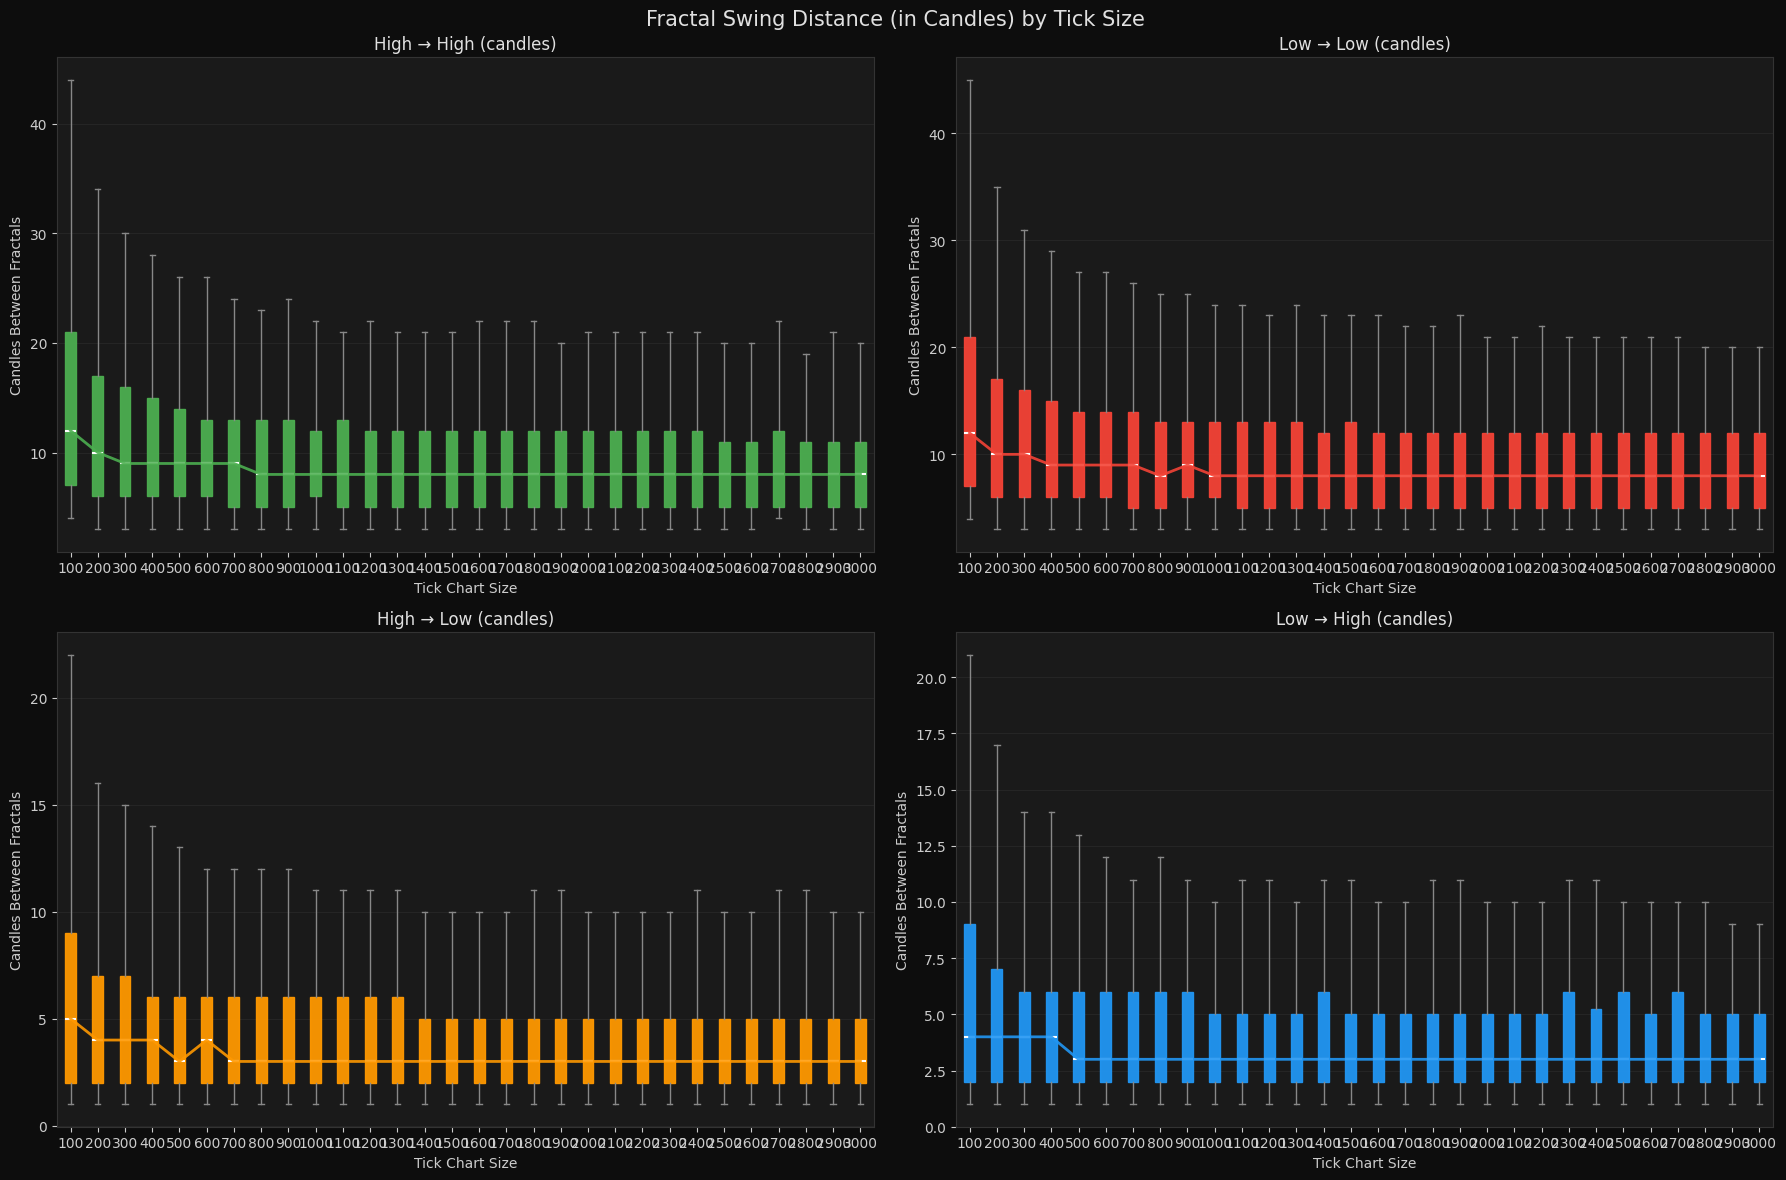

In [9]:
def williams_fractals_detailed(highs, lows, n=2):
    """Return bar indices and types for all fractal points."""
    indices = []
    types = []  # 1 = swing high, -1 = swing low

    for i in range(n, len(highs) - n):
        if all(highs[i] > highs[i - j] for j in range(1, n + 1)) and \
           all(highs[i] > highs[i + j] for j in range(1, n + 1)):
            indices.append(i)
            types.append(1)
        elif all(lows[i] < lows[i - j] for j in range(1, n + 1)) and \
             all(lows[i] < lows[i + j] for j in range(1, n + 1)):
            indices.append(i)
            types.append(-1)

    return np.array(indices), np.array(types)


# Subset of tick sizes for readability on box plots
tick_sizes_box = list(range(100, 3001, 100))

high_to_high_data = {}
low_to_low_data = {}
high_to_low_data = {}
low_to_high_data = {}

print(f"Computing fractal distances for {len(tick_sizes_box)} tick sizes...")

for size in tick_sizes_box:
    td.aggregate(method='tick', size=size)
    df = td.get_ohlc_dataframe()
    highs = df['High'].values
    lows = df['Low'].values

    frac_idx, frac_type = williams_fractals_detailed(highs, lows, n=2)
    if len(frac_idx) < 3:
        continue

    # Distances between consecutive same-type fractals
    high_indices = frac_idx[frac_type == 1]
    low_indices = frac_idx[frac_type == -1]

    if len(high_indices) > 1:
        high_to_high_data[size] = np.diff(high_indices)
    if len(low_indices) > 1:
        low_to_low_data[size] = np.diff(low_indices)

    # Distances between alternating types (high→low, low→high)
    h2l = []
    l2h = []
    for i in range(len(frac_idx) - 1):
        dist = frac_idx[i + 1] - frac_idx[i]
        if frac_type[i] == 1 and frac_type[i + 1] == -1:
            h2l.append(dist)
        elif frac_type[i] == -1 and frac_type[i + 1] == 1:
            l2h.append(dist)

    if h2l:
        high_to_low_data[size] = np.array(h2l)
    if l2h:
        low_to_high_data[size] = np.array(l2h)

# --- Plot ---
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.patch.set_facecolor('#0d0d0d')
fig.suptitle('Fractal Swing Distance (in Candles) by Tick Size', color='#e0e0e0', fontsize=15, y=0.98)

datasets = [
    (high_to_high_data, 'High → High (candles)', '#4CAF50'),
    (low_to_low_data, 'Low → Low (candles)', '#f44336'),
    (high_to_low_data, 'High → Low (candles)', '#FF9800'),
    (low_to_high_data, 'Low → High (candles)', '#2196F3'),
]

for ax, (data_dict, title, color) in zip(axes.flat, datasets):
    ax.set_facecolor('#1a1a1a')
    ax.tick_params(colors='#ccc')
    ax.xaxis.label.set_color('#ccc')
    ax.yaxis.label.set_color('#ccc')
    ax.title.set_color('#e0e0e0')
    for spine in ax.spines.values():
        spine.set_color('#333')
    ax.grid(True, alpha=0.2, color='#555', axis='y')

    sizes = sorted(data_dict.keys())
    box_data = [data_dict[s] for s in sizes]

    bp = ax.boxplot(box_data, positions=sizes, widths=40, patch_artist=True,
                    showfliers=False, whis=(5, 95),
                    medianprops=dict(color='white', linewidth=1.5),
                    whiskerprops=dict(color='#888'),
                    capprops=dict(color='#888'))

    for patch in bp['boxes']:
        patch.set_facecolor(color)
        patch.set_alpha(0.5)
        patch.set_edgecolor(color)

    # Overlay median line
    medians = [np.median(data_dict[s]) for s in sizes]
    ax.plot(sizes, medians, color=color, linewidth=2, alpha=0.9, zorder=5)

    ax.set_xlabel('Tick Chart Size')
    ax.set_ylabel('Candles Between Fractals')
    ax.set_title(title)
    ax.set_xlim(50, 3050)

plt.tight_layout()
plt.show()


In [3]:
import numpy as np
import pandas as pd
import sys
sys.path.insert(0, '.')

from Engine.TickData import TickData

# Load ES tick data and aggregate into 250-tick bars
td = TickData('./Data/ESTick.txt', timezone='America/Chicago')
td.aggregate(method='tick', size=1000)

tick_value = 12.50
contract_multiplier = 50
initial_equity = 100_000

ohlc = td.get_ohlc()
indices = td.get_indices()
timeframe = td.get_timeframe()
n_bars = len(ohlc)
close = ohlc[:, 3]

print(f'Bars: {n_bars:,}')
print(f'Date range: {indices[0]} to {indices[-1]}')


Loading tick data: ./Data/ESTick.txt
Loaded 23,033,489 ticks
Price range: 6751.50 - 7027.25

Aggregated 23,033,489 ticks into 23,033 bars (1000 tick)
Bars: 23,033
Date range: 2026-02-01 23:00:07.009440-06:00 to 2026-03-02 07:28:53.006560-06:00


In [ ]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def calculate_hurst(ts, max_lag=20):
    """
    Calculates the Hurst Exponent of a time series using the 
    standard deviation of differenced series method.
    """
    lags = np.arange(2, max_lag)
    if len(ts) < max_lag:
        return np.nan
        
    tau = [np.std(np.subtract(ts[lag:], ts[:-lag])) for lag in lags]
    tau_filtered = np.array(tau)[np.array(tau) > 0]
    lags_filtered = lags[:len(tau_filtered)]
    
    if len(tau_filtered) < 2:
        return np.nan
        
    poly = np.polyfit(np.log(lags_filtered), np.log(tau_filtered), 1)
    return poly[0]

# --- Calculation ---
close_series = pd.Series(close)
window_size = 50 
max_lag_size = int(window_size / 5)  # Use a fraction of the window size for lag

print(f"Calculating rolling Hurst Exponent (Window: {window_size})...")
hurst_rolling = close_series.rolling(window=window_size).apply(calculate_hurst, raw=True)

# Shift the Hurst array backward by the window size to align the "prediction" 
# with the start of the evaluated price action
hurst_shifted = hurst_rolling.shift(-window_size)

# Convert indices to datetime or clean strings if they aren't already for better Plotly formatting
x_axis = [i for i in range(len(close_series))]

# --- Plotly Interactive Dashboard ---

# Create a single plot with a secondary y-axis
fig = make_subplots()

# Plot: Close Price (Left Axis)
fig.add_trace(
    go.Scatter(
        x=x_axis, 
        y=close_series, 
        mode='lines', 
        name='Price', 
        line=dict(color='#2c3e50', width=1.5)
    ),
)

# Plot: Shifted Hurst Exponent (Right Axis)
fig.add_trace(
    go.Scatter(
        x=x_axis, 
        y=hurst_shifted, 
        mode='lines', 
        name='Hurst (Shifted)', 
        line=dict(color='#8e44ad', width=2)
    ),
)

# Add a dashed reference line at H = 0.5 (Random Walk boundary) linked to secondary Y-axis
fig.add_shape(
    type="line",
    x0=x_axis[0], y0=0.5, x1=x_axis[-1], y1=0.5,
    line=dict(color="black", width=1.5, dash="dash"),
    yref="y2"
)

# Add Background Shading Zones to indicate market regime structural boundaries
# Mean-Reverting Zone (0.0 to 0.5) linked to secondary Y-axis
fig.add_hrect(
    y0=0.0, y1=0.5, 
    fillcolor="rgba(39, 174, 96, 0.08)", 
    layer="below", 
    line_width=0,
    yref="y2"
)

# Trending Zone (0.5 to 1.0) linked to secondary Y-axis
fig.add_hrect(
    y0=0.5, y1=1.0, 
    fillcolor="rgba(192, 57, 43, 0.08)", 
    layer="below", 
    line_width=0,
    yref="y2"
)

# Layout Configuration for clean rendering
fig.update_layout(
    title_text=f"ES Futures Price vs. Shifted Hurst Exponent (Window: {window_size})",
    height=700,
    showlegend=True,
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1),
    hovermode='x unified',
    template='plotly_white',
    margin=dict(l=60, r=60, t=80, b=50)
)

# Set axis titles and ranges
fig.update_xaxes(title_text="Time")
fig.update_yaxes(title_text="Price ($)", secondary_y=False)
fig.update_yaxes(title_text="Hurst Exponent (H)", range=[0, 1], secondary_y=True)

# Render the interactive chart inside your Jupyter notebook
fig.show()

Calculating rolling Hurst Exponent (Window: 50)...
